# Exploring ERA5 2m temperature with xarray

## 1. Opening the data

In [1]:
import pandas as pd
import xarray as xr
from pathlib import Path
import matplotlib.pyplot as plt
from dask.diagnostics import ProgressBar

path = "gs://weatherbench2/datasets/era5/1959-2022-6h-64x32_equiangular_with_poles_conservative.zarr"
ds = xr.open_zarr(path, storage_options={"token": "anon"})
ds

<xarray.Dataset> Size: 81GB
Dimensions:                                           (time: 92040,
                                                       longitude: 64,
                                                       latitude: 32, level: 13)
Coordinates:
  * time                                              (time) datetime64[ns] 736kB ...
  * longitude                                         (longitude) float64 512B ...
  * latitude                                          (latitude) float64 256B ...
  * level                                             (level) int64 104B 50 ....
Data variables: (12/38)
    10m_u_component_of_wind                           (time, longitude, latitude) float32 754MB dask.array<chunksize=(100, 64, 32), meta=np.ndarray>
    10m_v_component_of_wind                           (time, longitude, latitude) float32 754MB dask.array<chunksize=(100, 64, 32), meta=np.ndarray>
    10m_wind_speed                                    (time, longitude, latitude) float32 754MB dask.array<chunksize=(100, 64, 32), meta=np.ndarray>
    2m_temperature                                    (time, longitude, latitude) float32 754MB dask.array<chunksize=(100, 64, 32), meta=np.ndarray>
    angle_of_sub_gridscale_orography                  (longitude, latitude) float32 8kB dask.array<chunksize=(64, 32), meta=np.ndarray>
    anisotropy_of_sub_gridscale_orography             (longitude, latitude) float32 8kB dask.array<chunksize=(64, 32), meta=np.ndarray>
    ...                                                ...
    type_of_high_vegetation                           (longitude, latitude) float32 8kB dask.array<chunksize=(64, 32), meta=np.ndarray>
    type_of_low_vegetation                            (longitude, latitude) float32 8kB dask.array<chunksize=(64, 32), meta=np.ndarray>
    u_component_of_wind                               (time, level, longitude, latitude) float32 10GB dask.array<chunksize=(100, 13, 64, 32), meta=np.ndarray>
    v_component_of_wind                               (time, level, longitude, latitude) float32 10GB dask.array<chunksize=(100, 13, 64, 32), meta=np.ndarray>
    vertical_velocity                                 (time, level, longitude, latitude) float32 10GB dask.array<chunksize=(100, 13, 64, 32), meta=np.ndarray>
    wind_speed                                        (time, level, longitude, latitude) float32 10GB dask.array<chunksize=(100, 13, 64, 32), meta=np.ndarray>

## 2. A global snapshot: 1 July 2020, 12:00 UTC

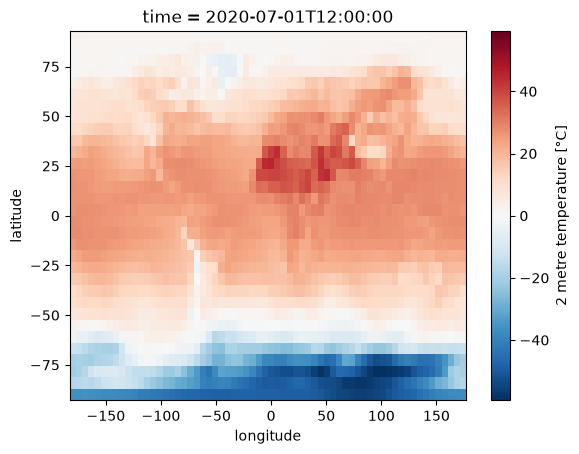

In [2]:
t2m_july = ds['2m_temperature'].sel(time='2020-07-01T12:00')
t2m_july = t2m_july - 273.15
t2m_july.attrs['units'] = '°C'
t2m_july = t2m_july.assign_coords(longitude=((t2m_july['longitude'] + 180)%360)-180).sortby("longitude")
t2m_july.plot(x="longitude", y="latitude")

## 3. Time series: Darmstadt and Reading

In [3]:
#the 5.625° grid cell containing Darmstadt
darmstadt = ds["2m_temperature"].sel(latitude=49.9, longitude=8.65, method="nearest")

#the 5.625° grid cell containing Reading
reading = ds["2m_temperature"].sel(latitude=51.4, longitude=360-0.97, method="nearest")

In [4]:
def resampled_mean_celsius(series, start, end, time_frame):
    """Mean 2 m temperature in °C over regular time bins, between start and end."""
    series = series.sel(time=slice(start, end))
    series = series - 273.15
    series = series.resample(time=time_frame).mean()
    series.attrs['units'] = '°C'
    return series

reading_daily = resampled_mean_celsius(reading, "2020-01-01", "2020-12-31", "1D")
darmstadt_daily = resampled_mean_celsius(darmstadt, "2020-01-01", "2020-12-31", "1D")

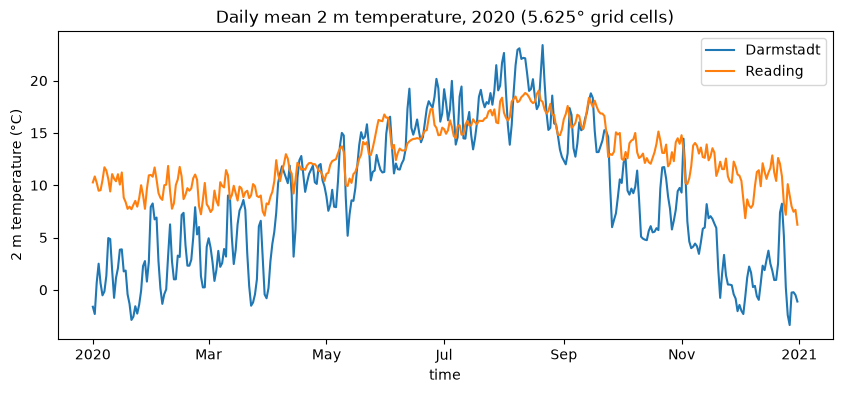

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))     # one figure, one axes

darmstadt_daily.plot(ax=ax, label="Darmstadt")   # draw on that axes
reading_daily.plot(ax=ax, label="Reading")       # same axes, so same plot

ax.set_ylabel("2 m temperature (°C)")
ax.set_title("Daily mean 2 m temperature, 2020 (5.625° grid cells)")
ax.legend()

In [6]:
START, END = "2020-01-01", "2020-12-31"

darmstadt_monthly = resampled_mean_celsius(darmstadt, START, END, "1MS")
reading_monthly = resampled_mean_celsius(reading, START, END, "1MS")

darmstadt_amplitude = float(darmstadt_monthly.max() - darmstadt_monthly.min())
reading_amplitude = float(reading_monthly.max() - reading_monthly.min())

pd.DataFrame(
    {"Seasonal amplitude (°C)": [darmstadt_amplitude, reading_amplitude]},
    index=["Darmstadt", "Reading"],
).round(1)

,Seasonal amplitude (°C)
Darmstadt,17.6
Reading,8.3


## 4. Climatology

In [36]:
#A local Zarr copy avoids re-downloading 30 years of global chunks for one grid point.

LOCAL = Path("data/darmstadt_1991_2020.zarr")

if LOCAL.exists():
    darmstadt_1991_2020 = xr.open_zarr(LOCAL)["2m_temperature"].load()
else:
    with ProgressBar():
        darmstadt_1991_2020 = darmstadt.sel(time=slice("1991", "2020")).load()
    dset = darmstadt_1991_2020.to_dataset(name="2m_temperature")
    for variable in dset.variables.values():     # data variable *and* coordinates
        variable.encoding = {}
    dset.to_zarr(LOCAL)

def climatology_by_timespan_celsius(series, timespan):
    """Calculate the climatology for a given timespan in Celsius."""
    series_timespan_climatology = series.groupby(timespan).mean()
    series_timespan_climatology = series_timespan_climatology - 273.15
    series_timespan_climatology.attrs["units"] = "°C"
    return series_timespan_climatology

def plot_against_normal(ax, x, normal, observed, title, xlabel):
    """Plot observed values against a climatological normal on the given axes."""
    ax.plot(x, normal, marker="o", label="1991-2020 normal")
    ax.plot(x, observed, marker="x", label="2020")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("2 m temperature (°C)")
    ax.set_title(title)
    ax.legend()


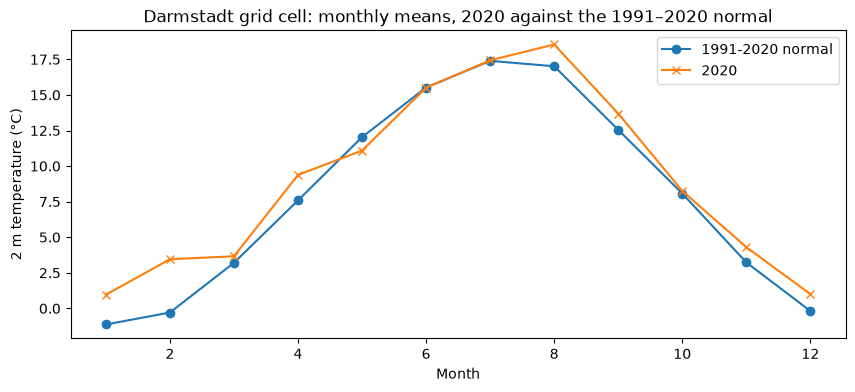

In [40]:
darmstadt_monthly_climatology = climatology_by_timespan_celsius(darmstadt_1991_2020, 'time.month')

fig, ax = plt.subplots(figsize=(10, 4))     # one figure, one axes
plot_against_normal(ax, darmstadt_monthly_climatology.month, darmstadt_monthly_climatology, darmstadt_monthly, "Darmstadt grid cell: monthly means, 2020 against the 1991–2020 normal", "Month")

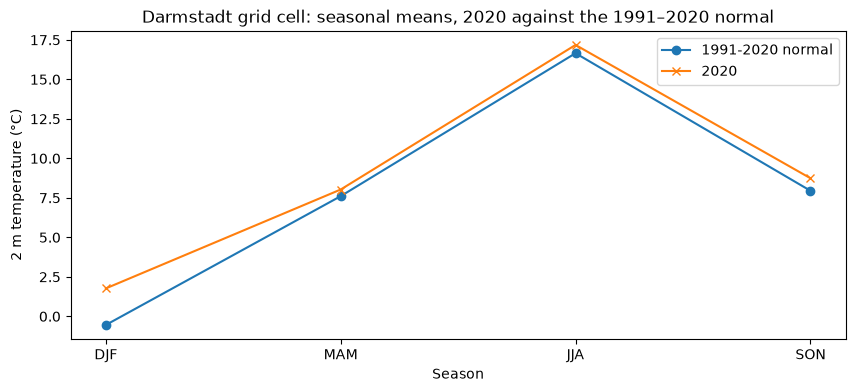

In [41]:
darmstadt_seasonal_climatology = climatology_by_timespan_celsius(darmstadt_1991_2020, 'time.season')
darmstadt_seasonal_climatology = darmstadt_seasonal_climatology.sel(season=["DJF", "MAM", "JJA", "SON"])

darmstadt_seasonal_2020 = climatology_by_timespan_celsius(darmstadt_1991_2020.sel(time='2020'), 'time.season')
darmstadt_seasonal_2020 = darmstadt_seasonal_2020.sel(season=["DJF", "MAM", "JJA", "SON"])

fig, ax = plt.subplots(figsize=(10, 4))     
plot_against_normal(ax, darmstadt_seasonal_climatology.season, darmstadt_seasonal_climatology, darmstadt_seasonal_2020, "Darmstadt grid cell: seasonal means, 2020 against the 1991–2020 normal", "Season")